In [2]:
import os
os.chdir("D:/tmp_workplace/dynamic_structure/260403/UTR/PDCoV/virion/PPV_Sensitivity")
import matplotlib.pyplot as plt
import numpy as np

In [3]:
def load_ct(file):
    expriment, start, end = file.replace(".ct","").split("_")
    start = int(start)
    end = int(end)
    length = end - start + 1

    pairs = []
    with open(file,"r")as f:
        lines = f.readlines()
        for i, line in enumerate(lines):
            if i == 0:
                continue
            else:
                sub = line.strip().split()
                if len(sub) < 3:
                    continue
                left = int(sub[0])
                right = int(sub[4])
                if (left<right) and (right!=0):
                    pairs.append((left+start-1,right+start-1))
    return pairs, start, end

def load_ct_raw(file):
    start, end = file.replace(".ct","").split("_")[-2:]
    start = int(start)
    end = int(end)

    pairs = []
    with open(file,"r")as f:
        lines = f.readlines()
        for i, line in enumerate(lines):
            sub = line.strip().split()
            if len(sub) < 3:
                continue
            left = int(sub[0])
            right = int(sub[4])
            if (left<right) and (right!=0):
                pairs.append((left,right))
    return pairs, start, end

def evaluate_structure_accuracy(raw_pred_pairs, pred_start, pred_end, raw_ref_pairs, ref_start, ref_end, tolerance=5):
    """
    评估RNA二级结构预测的准确性（宽松匹配模式）
    参数:
    tolerance: int, 碱基位置允许的偏移量（默认±5）
    返回:
    sensitivity: float, 敏感性
    ppv: float, 阳性预测值
    tp: int, 正确预测的碱基对数量
    fp: int, 错误预测的碱基对数量
    fn: int, 漏报的碱基对数量
    """
    
    def is_match(pair1, pair2, tol):
        """检查两个碱基对是否在容忍范围内匹配"""
        i1, j1 = pair1
        i2, j2 = pair2
        
        # 检查正向配对
        if abs(i1 - i2) <= tol and abs(j1 - j2) <= tol:
            return True
        
        return False
    
    overlap_start = min([pred_start, ref_start])
    overlap_end = max([pred_end, ref_end])

    new_pred_pairs = [(i,j) for i,j in raw_pred_pairs if (i>=overlap_start) and (j<=overlap_end)]
    new_ref_pairs = [(i,j) for i,j in raw_ref_pairs if (i>=overlap_start) and (j<=overlap_end)]
    
    pred_set = set(new_pred_pairs)
    ref_set = set(new_ref_pairs)
    
    tp = 0  # 正确预测
    fp = 0  # 错误预测
    fn = 0  # 漏报
    
    # 用于记录已匹配的参考碱基对，避免重复匹配
    matched_ref_pairs = set()
    
    # 1. 遍历所有预测的碱基对，寻找匹配的参考碱基对
    for pred_pair in pred_set:
        matched = False
        
        # 寻找是否有参考碱基对与之匹配
        for ref_pair in ref_set:
            if is_match(pred_pair, ref_pair, tolerance):
                # 避免重复匹配同一个参考碱基对
                if ref_pair not in matched_ref_pairs:
                    tp += 1
                    matched_ref_pairs.add(ref_pair)
                    matched = True
                    break
        
        # 如果没有找到匹配的参考碱基对，则是错误预测
        if not matched:
            fp += 1
    
    # 2. 计算漏报数量：参考中有但未被匹配的
    #fn = len(ref_set) - len(matched_ref_pairs)
    fn = len(ref_set) - tp
    
    # 3. 计算指标
    # 敏感性 = TP / (TP + FN)
    sensitivity = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    
    # 阳性预测值 = TP / (TP + FP)
    ppv = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    
    return sensitivity, ppv

In [4]:
vric_5, vric_5_start, vric_5_end = load_ct_raw("GSE254992_PDCoV_1_540.ct")
vric_3, vric_3_start, vric_3_end = load_ct_raw("GSE254992_PDCoV_24970_25420.ct")
river_5, river_5_start, river_5_end = load_ct("RIVER_1_540.ct")
river_3, river_3_start, river_3_end = load_ct("RIVER_24970_25420.ct")

In [5]:
river_5_sensitivity, river_5_ppv = evaluate_structure_accuracy(river_5, river_5_start, river_5_end, vric_5, vric_5_start, vric_5_end, tolerance=5)
river_3_sensitivity, river_3_ppv = evaluate_structure_accuracy(river_3, river_3_start, river_3_end, vric_3, vric_3_start, vric_3_end, tolerance=5)

In [6]:
ppv = [river_5_ppv,river_3_ppv]
sensitivity = [river_5_sensitivity,river_3_sensitivity]
labels = ["river_5","river_3"]
colors = ["#FF0303","#1AFF00"]

print(np.mean(ppv),np.mean(sensitivity))

0.7763415067519546 0.7869462599854757


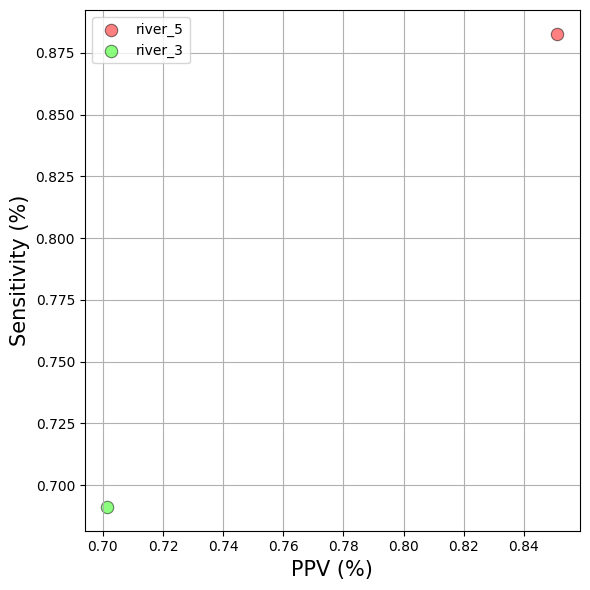

In [7]:
# 
fig, ax = plt.subplots(figsize=(6,6))

for i in range(2):
    ax.scatter(ppv[i], sensitivity[i],
           c=colors[i],        # 填充色
           edgecolors="#000000",     # 轮廓色，'k'=black，也可以用 '#000000'、'white' 等
           linewidths=0.8,     # 轮廓线宽，默认 1，可自己调
           alpha=0.5,
           s=80,
           label=labels[i])

ax.set_xlabel('PPV (%)', fontsize=15)
ax.set_ylabel('Sensitivity (%)', fontsize=15)

ax.grid(True)
fig.tight_layout()
plt.legend()

plt.savefig("utr_sensitivity_ppv_scatter.pdf")
plt.show()